# 6. Field Ablation, Representation Baselines & Method Robustness

**What you will learn:**
1. Why **every field family** ($\rho_\sigma$, $K_\sigma$, and the flux triad $\varphi_\sigma, \psi_\sigma, J_\sigma$) contributes non-redundant discriminative power across `990` settings (`Top-1..Top-10`).
2. Quantitative comparison against **Order Parameters**, **CROCKER positional Betti curves**, **Single-Scale fields**, and **Value Quantile Distributions** under the exact same rank/SNF/AP pipeline.
3. Stability checks: **$\mathrm{SO}(2)$ rotation invariance**, **Affinity Propagation convergence** across damping/noise/window settings, and why **mutual-rank balanced SNF** avoids collapse.

In [1]:
import pickle, re, sys
from pathlib import Path
from IPython.display import Image, display
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path[:0] = [str(ROOT / "analysis"), str(ROOT / "src"), str(ROOT)]

import figlib as L
import make_figures as M
L.style()

PAPER = ROOT / "results" / "epuck" / "paper"
load = lambda p: pickle.load(open(p, "rb"))

## 1. Eleven-Combination Field Ablation (`990` Settings per Variant)

* **Density ($\rho_\sigma$)** alone sees static presence (missing velocities).
* **Kinetic intensity ($K_\sigma$)** achieves the strongest single-field purity (`0.960` median) yet has `0` error-free settings on its own.
* Adding **Jacobi coupling ($J_\sigma$)** lifts error-free settings (`406` $\to$ `440/990`, and `78` $\to$ `98/99` on Top-1) and stops pooled cluster counts from dropping unexpectedly as controllers are added.

saved /home/ndinga/Documents/paper_topological_kinematics/figures/fig_ablation.pdf


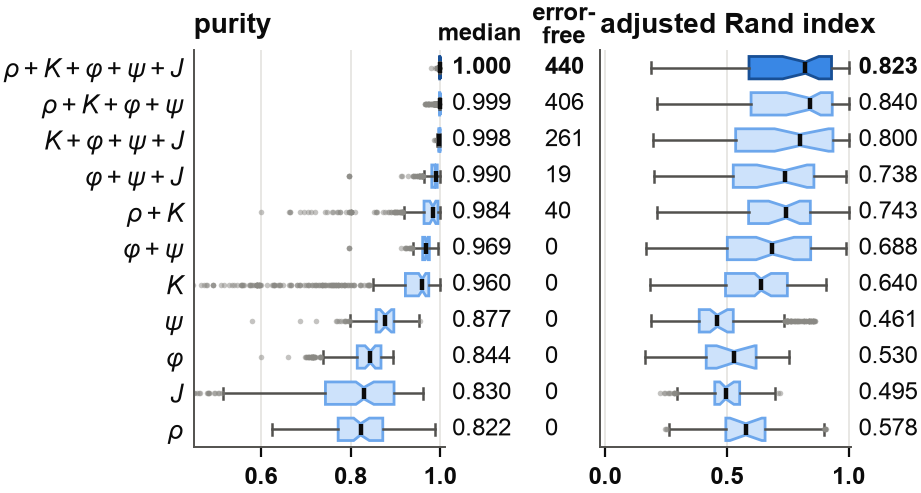

In [2]:
M.fig_ablation()
display(Image(filename=str(ROOT / "figures/fig_ablation.png"), width=900))

## 2. Baselines Under the Identical Fusion & Clustering Pipeline

Let's parse the exact verified baseline numbers from `manuscript/tables/baselines.tex` (`Top-1` & `Top-10`) and plot **Purity vs ARI vs Error-Free Settings** side by side! Notice that on `Top-10`, **Persistence Diagrams** keep full purity (`1.000`) and higher ARI (`0.762`) than Value Quantiles (`0.660`), CROCKER (`0.667`), or Order Parameters (`0.362`), and uniquely unlock gradient attribution (`Notebook 07`).

Top-1 Comparison (250 runs) & Top-10 Comparison (2,500 runs):
  Representation               C* / C      Purity     ARI
  Persistence diagrams         11 (17)      1.000   0.762
  Value distributions          12 (14)      0.998   0.660
  Diagrams and values          10 (16)      1.000   0.787
  CROCKER curves of positions  7 (21)       0.804   0.667
  Order parameters             16 (11)      0.797   0.362
  Finest scale only            C=58         0.999   0.157
  Coarsest scale only          C=78         0.992   0.114
  Scales averaged              C=66         0.999   0.134


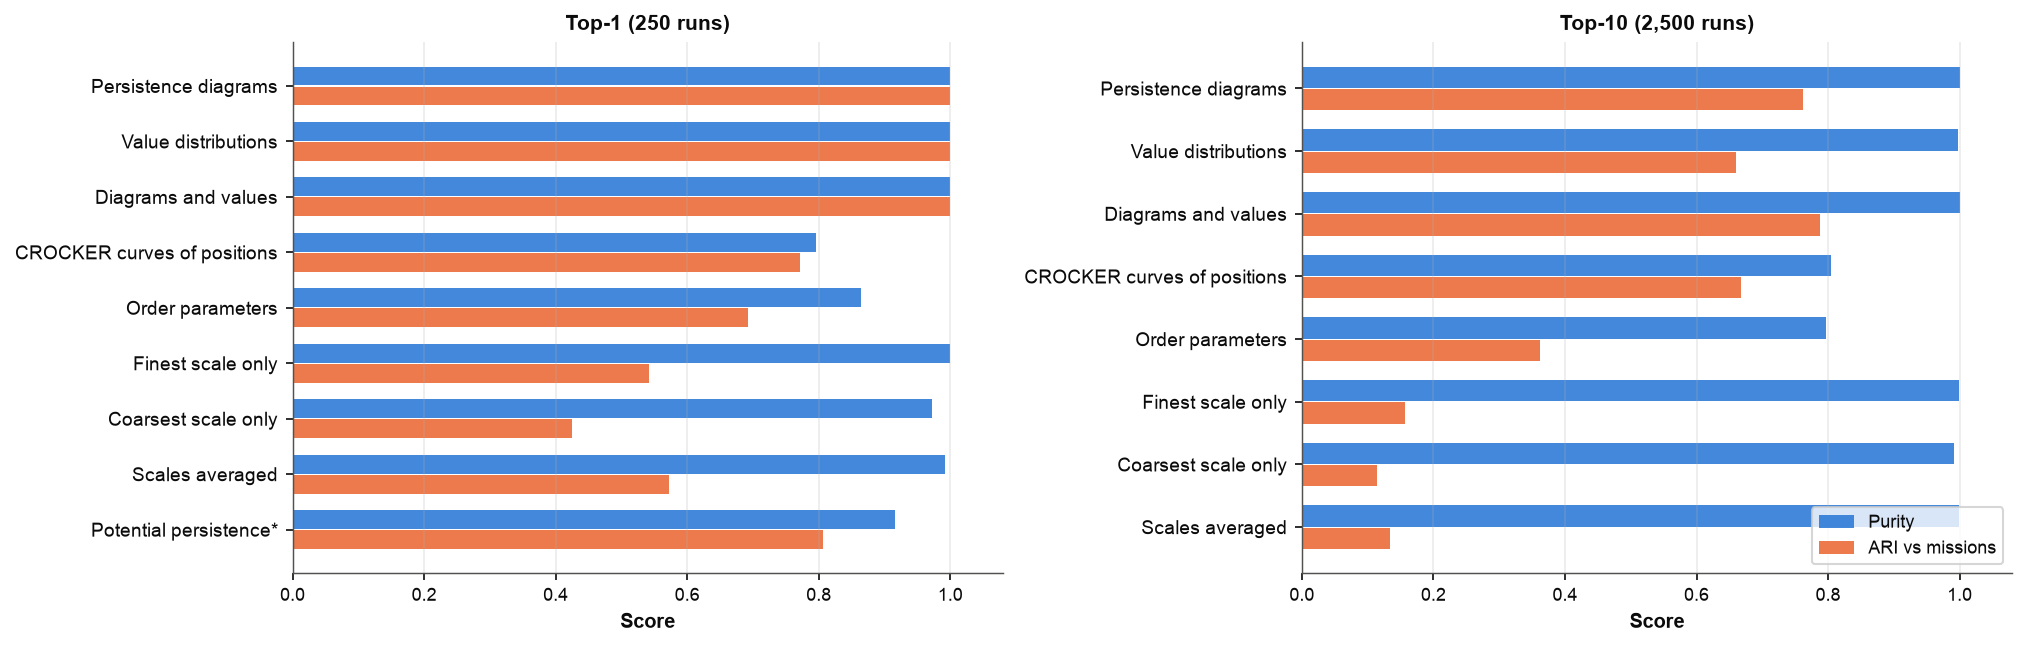

In [3]:
def parse_num(s):
    s = s.strip().replace("$C=", "").replace("$", "")
    m = re.match(r"([0-9.]+)", s)
    return float(m.group(1)) if m else np.nan

rows_top1, rows_top10 = [], []
section = 1
for line in (ROOT / "manuscript/tables/baselines.tex").read_text().splitlines():
    if "Top-10" in line:
        section = 10
    elif "&" in line and not line.strip().startswith("Representation"):
        parts = [p.strip() for p in line.replace("\\methodrow", "").replace("\\\\", "").split("&")]
        if len(parts) >= 7:
            name = parts[0].replace("\\quad ", "").replace("$^{*}$", "*").strip()
            cstr = parts[1].replace("$", "").strip()
            rec = (name, cstr, parse_num(parts[2]), parse_num(parts[5]))
            (rows_top1 if section == 1 else rows_top10).append(rec)

print("Top-1 Comparison (250 runs) & Top-10 Comparison (2,500 runs):")
print(f"  {'Representation':<28s} {'C* / C':<10s} {'Purity':>7s} {'ARI':>7s}")
for n, cstr, pur, ari in rows_top10:
    print(f"  {n:<28s} {cstr:<10s} {pur:7.3f} {ari:7.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13.6, 4.4))
for ax, rows, tit in ((axes[0], rows_top1, "Top-1 (250 runs)"), (axes[1], rows_top10, "Top-10 (2,500 runs)")):
    names_b = [r[0] for r in rows]
    purs = [r[2] for r in rows]
    aris = [r[3] for r in rows]
    y_pos = np.arange(len(rows))[::-1]
    ax.barh(y_pos + 0.18, purs, height=0.34, color=L.MCOL[0], alpha=0.88, label="Purity")
    ax.barh(y_pos - 0.18, aris, height=0.34, color=L.MCOL[1], alpha=0.88, label="ARI vs missions")
    ax.set_yticks(y_pos); ax.set_yticklabels(names_b, fontsize=9)
    ax.set_xlim(0, 1.08); ax.set_xlabel("Score"); ax.set_title(tit, fontweight="bold")
    ax.grid(axis="x", alpha=0.25)
axes[1].legend(loc="lower right", fontsize=8.5)
plt.tight_layout(); plt.show()

## 3. Robustness Checks: Rotation Invariance, AP Convergence & Fusion Designs

Let's inspect three structural guarantees directly from stored verification runs:
1. **Rotation Invariance (`results/invariance_check/report.pkl`)** — Distance between original and rotated runs compared against within-mission scatter.
2. **Affinity Propagation Convergence (`ap_check.pkl`)** — Checking `99/99` convergence, iteration distributions, longer patience windows (`200`, `400`), higher ceiling (`5000`), and damping changes (`0.8`, `0.95`).
3. **Fusion Designs (`designs.tex`)** — Why single-stage moment-balanced SNF succeeds where `20` flat field views (`C*=4`), stacked hierarchical SNF (`1/9` monotone), or removing diffusion (`C=12`) fail.

Rotation invariance report entries: [(39, 'rho', 0), (39, 'K', 0), (39, 'phi', 0), (39, 'psi', 0), (39, 'J', 0), (39, 'rho', 1), (39, 'K', 1), (39, 'phi', 1), (39, 'psi', 1), (39, 'J', 1), (39, 'rho', 2), (39, 'K', 2), (39, 'phi', 2), (39, 'psi', 2), (39, 'J', 2), (39, 'rho', 3), (39, 'K', 3), (39, 'phi', 3), (39, 'psi', 3), (39, 'J', 3), (56, 'rho', 0), (56, 'K', 0), (56, 'phi', 0), (56, 'psi', 0), (56, 'J', 0), (56, 'rho', 1), (56, 'K', 1), (56, 'phi', 1), (56, 'psi', 1), (56, 'J', 1), (56, 'rho', 2), (56, 'K', 2), (56, 'phi', 2), (56, 'psi', 2), (56, 'J', 2), (56, 'rho', 3), (56, 'K', 3), (56, 'phi', 3), (56, 'psi', 3), (56, 'J', 3), (109, 'rho', 0), (109, 'K', 0), (109, 'phi', 0), (109, 'psi', 0), (109, 'J', 0), (109, 'rho', 1), (109, 'K', 1), (109, 'phi', 1), (109, 'psi', 1), (109, 'J', 1), (109, 'rho', 2), (109, 'K', 2), (109, 'phi', 2), (109, 'psi', 2), (109, 'J', 2), (109, 'rho', 3), (109, 'K', 3), (109, 'phi', 3), (109, 'psi', 3), (109, 'J', 3), (175, 'rho', 0), (175, 'K', 0),

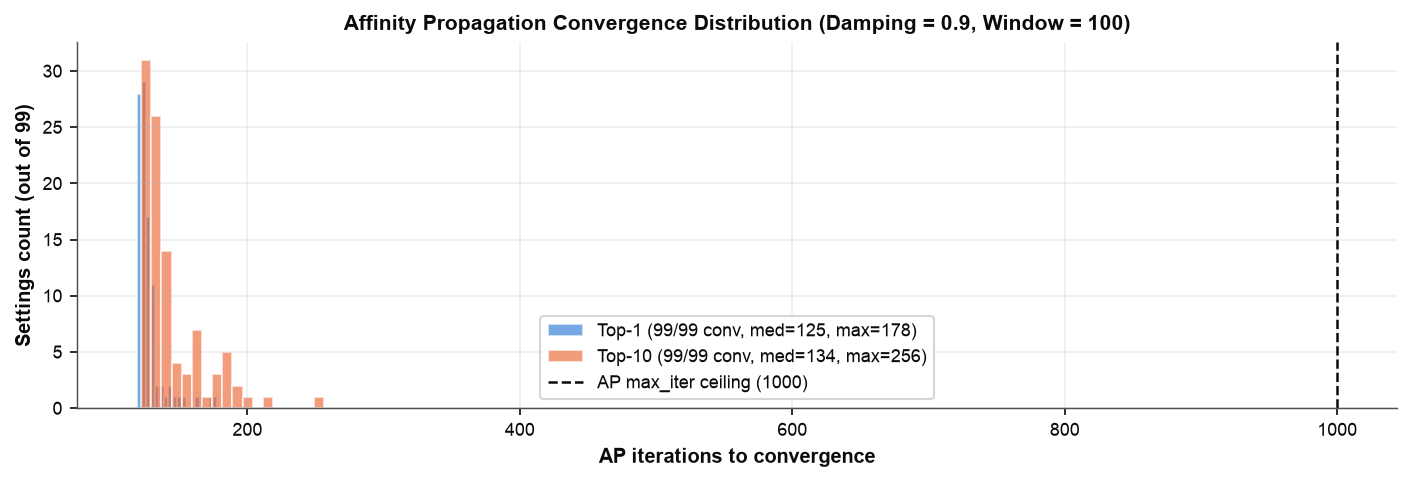

--- designs.tex ---
\begin{tabularx}{\linewidth}{@{}>{\raggedright\arraybackslash}Xccccc@{}}
\toprule
Fusion & Modal & Perfect & $C\le2$ & \makecell{Median\\purity} & Monotone\\
\midrule
\methodrow Balanced views, SNF across scales (the method) & $C^\star=5$ (84) & 83 & 0 & 1.000 & 9/9\\
No diffusion & $C=12$ & 0 & 0 & 0.992 & 9/9\\
Flux re-ranked before balancing & $C^\star=5$ (88) & 88 & 0 & 1.000 & 9/9\\
One SNF, 12 views, one per moment and scale & $C^\star=5$ (84) & 79 & 0 & 1.000 & 9/9\\
One SNF, 20 field views & $C^\star=4$ (57) & 26 & 0 & 0.800 & 9/9\\
Three stacked SNF stages & $C^\star=5$ (50) & 4 & 0 & 0.812 & 1/9\\
\bottomrule
\end{tabularx}



In [4]:
ir = load(ROOT / "results/invariance_check/report.pkl")
print("Rotation invariance report entries:", list(ir.get("report", ir).keys()) if isinstance(ir, dict) else len(ir))
inv_tab = ROOT / "manuscript/tables/invariance.tex"
if inv_tab.exists():
    print(inv_tab.read_text())

AC = load(PAPER / "ap_check.pkl")
fig, ax = plt.subplots(figsize=(9.5, 3.3))
for top, col in ((1, L.MCOL[0]), (10, L.MCOL[1])):
    ref = AC[(top, "paper")]
    iters = np.array(ref["iterations"])
    ax.hist(iters, bins=18, alpha=0.65, color=col, edgecolor="white", label=f"Top-{top} (99/99 conv, med={np.median(iters):.0f}, max={iters.max()})")
    print(f"Top-{top} paper AP: {ref['converged']}/{len(iters)} converged | median={np.median(iters):.0f} | max={iters.max()}")
    for (t_, name), r in AC.items():
        if t_ == top and name != "paper":
            print(f"   {name:14s}: identical {r['settings_identical']}/{len(iters)}, min ARI={r['settings_ari_min']:.3f}, consensus ARI={r['consensus_ari']:.3f}")
ax.axvline(1000, color=L.INK, ls="--", lw=1.2, label="AP max_iter ceiling (1000)")
ax.set_xlabel("AP iterations to convergence"); ax.set_ylabel("Settings count (out of 99)")
ax.set_title("Affinity Propagation Convergence Distribution (Damping = 0.9, Window = 100)", fontweight="bold")
ax.legend(fontsize=8.5); ax.grid(alpha=0.2)
plt.tight_layout(); plt.show()

for dname in ("designs", "standard_snf"):
    p = ROOT / f"manuscript/tables/{dname}.tex"
    if p.exists():
        print(f"--- {dname}.tex ---")
        print(p.read_text())